# Demonstrate a working controller

## 1. Set up the notebook

Do imports.

In [69]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, IFrame, HTML
from ae483.tools import *
from ae483.mytools import *
from ae483.design import *

Define name of file with flight data.

In [70]:
filename = 'demonstration_data.json'

## 2. Check mocap coverage

Check coverage of mocap data.

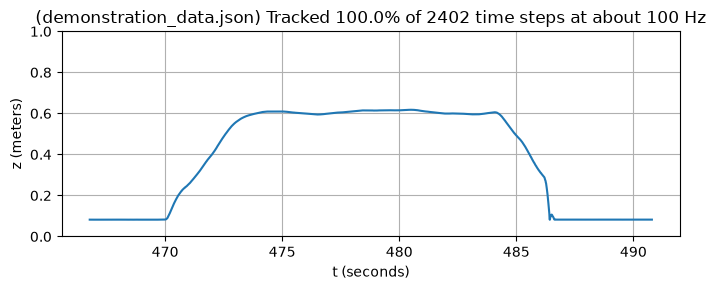

In [71]:
check_mocap_coverage(filename)

## 3. Show results

Load flight data.

In [72]:
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data(filename)

Resample and parse drone data.

In [73]:
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0., # <-- FIXME
    t_max_offset=0., # <-- FIXME
)

# time
t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

Resample and parse mocap data (with an optimal time shift and with coordinate transformation).

In [74]:
data_mocap = sync_data_mocap(
    raw_data_mocap,
    t,
    p_z,
    do_transform=True,      # <-- whether to align mocap data in space
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1.,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)

p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

Plot $x, y$ data.

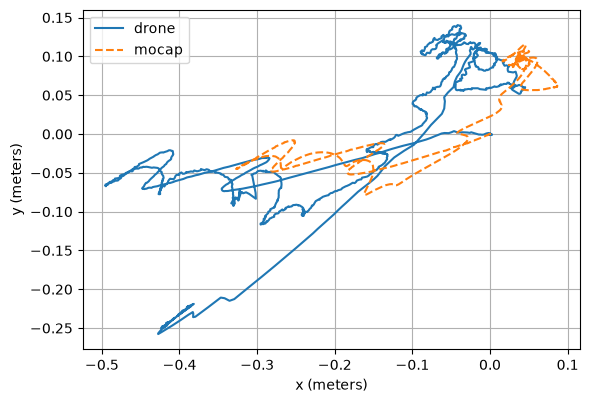

In [75]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), tight_layout=True)
ax.plot(p_x, p_y, label='drone')
ax.plot(p_x_mocap, p_y_mocap, '--', label='mocap')
ax.set_aspect('equal')
ax.set_xlabel('x (meters)')
ax.set_ylabel('y (meters)')
ax.legend()
ax.grid()

Plot all data.

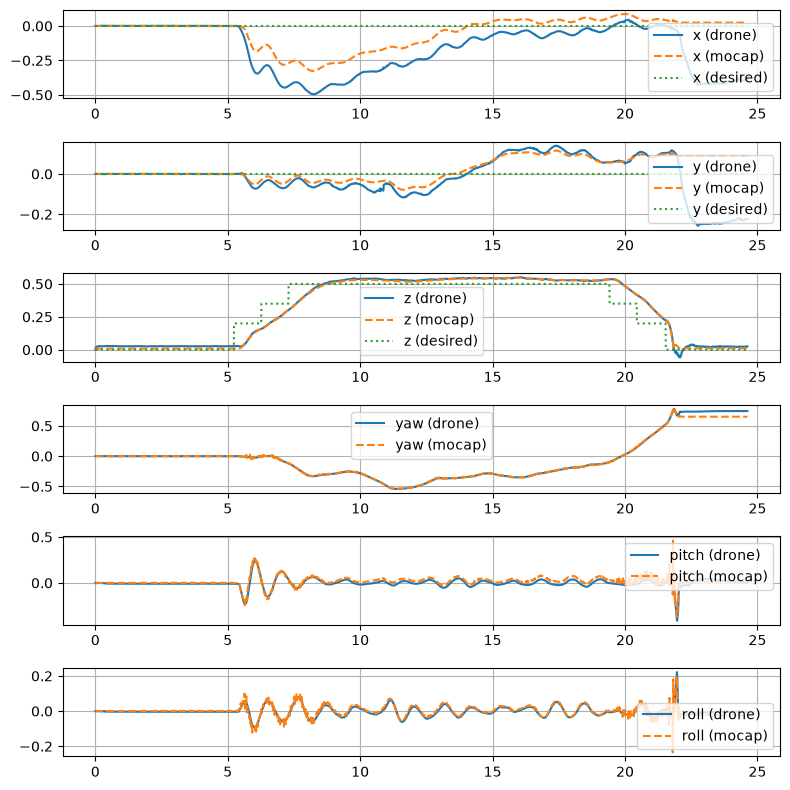

In [76]:
fig, (ax_x, ax_y, ax_z, ax_psi, ax_theta, ax_phi) = plt.subplots(6, 1, figsize=(8, 8), tight_layout=True)

ax_x.plot(t, p_x, label='x (drone)')
ax_x.plot(t, p_x_mocap, '--', label='x (mocap)')
ax_x.plot(t, p_x_des, ':', label='x (desired)')
ax_x.legend()
ax_x.grid()

ax_y.plot(t, p_y, label='y (drone)')
ax_y.plot(t, p_y_mocap, '--', label='y (mocap)')
ax_y.plot(t, p_y_des, ':', label='y (desired)')
ax_y.legend()
ax_y.grid()

ax_z.plot(t, p_z, label='z (drone)')
ax_z.plot(t, p_z_mocap, '--', label='z (mocap)')
ax_z.plot(t, p_z_des, ':', label='z (desired)')
ax_z.legend()
ax_z.grid()

ax_psi.plot(t, psi, label='yaw (drone)')
ax_psi.plot(t, psi_mocap, '--', label='yaw (mocap)')
ax_psi.legend()
ax_psi.grid()

ax_theta.plot(t, theta, label='pitch (drone)')
ax_theta.plot(t, theta_mocap, '--', label='pitch (mocap)')
ax_theta.legend()
ax_theta.grid()

ax_phi.plot(t, phi, label='roll (drone)')
ax_phi.plot(t, phi_mocap, '--', label='roll (mocap)')
ax_phi.legend()
ax_phi.grid()

Show the gains that were used to produce these results.

In [77]:
show_gains(filename)

Control gains, designed 2026-10-13T17:19:14:
tau_x_cmd:     eq   0.0000    p_y  -0.0013    phi   0.0030    v_y  -0.0009    w_x   0.0005  tau_x   1.2069    e_y  -0.0002
tau_y_cmd:     eq   0.0000    p_x   0.0013  theta   0.0030    v_x   0.0009    w_y   0.0005  tau_y   1.2133    e_x   0.0002
    tau_z:     eq   0.0000    psi   0.0003    w_z   0.0001
      f_z:     eq   0.3139    p_z   0.1393    v_z   0.0946    e_z   0.0243


Show links to a video of your hardware flight test (change the url as appropriate) that was previously uploaded to [Illinois Mediaspace](https://mediaspace.illinois.edu/) and published as **Unlisted**.

In [78]:
# FIXME (REPLACE URL TO SHOW A VIDEO OF YOUR FLIGHT)
mediaspace('https://mediaspace.illinois.edu/media/t/1_k7zuj375')

**Modify this cell** to describe three things:

* Your design.
* Your flight test.
* Your results, in particular making clear if these results satisfy requirements. (Feel free to add code to verify these requirements.)

In [79]:
# Requirement verification
# px within [-0.5, 0.5] meters
# py within [-0.5, 0.5] meters
# pz within [0.1, 1.1] meters

bounds = {
    'x': (-0.5, 0.5),
    'y': (-0.5, 0.5),
    'z': (0.1, 1.1),
}

def check_bounds(label, positions):
    print(f'--- {label} ---')
    all_ok = True
    for axis, (lo, hi) in bounds.items():
        p = np.asarray(positions[axis])
        valid = ~np.isnan(p)
        p = p[valid]
        p_min, p_max = np.min(p), np.max(p)
        n_out = np.sum((p < lo) | (p > hi))
        ok = (n_out == 0)
        all_ok = all_ok and ok
        print(f'p_{axis}: min = {p_min:+.3f}, max = {p_max:+.3f}, '
              f'bounds = [{lo:+.1f}, {hi:+.1f}], '
              f'samples out of bounds = {n_out}/{len(p)} -> {"PASS" if ok else "FAIL"}')
    print(f'Overall: {"PASS" if all_ok else "FAIL"}\n')
    return all_ok

drone_ok = check_bounds('Drone (onboard estimate)', {'x': p_x, 'y': p_y, 'z': p_z})
mocap_ok = check_bounds('Mocap (ground truth)', {'x': p_x_mocap, 'y': p_y_mocap, 'z': p_z_mocap})

--- Drone (onboard estimate) ---
p_x: min = -0.496, max = +0.045, bounds = [-0.5, +0.5], samples out of bounds = 0/2463 -> PASS
p_y: min = -0.258, max = +0.140, bounds = [-0.5, +0.5], samples out of bounds = 0/2463 -> PASS
p_z: min = -0.059, max = +0.551, bounds = [+0.1, +1.1], samples out of bounds = 871/2463 -> FAIL
Overall: FAIL

--- Mocap (ground truth) ---
p_x: min = -0.327, max = +0.087, bounds = [-0.5, +0.5], samples out of bounds = 0/2463 -> PASS
p_y: min = -0.078, max = +0.116, bounds = [-0.5, +0.5], samples out of bounds = 0/2463 -> PASS
p_z: min = +0.009, max = +0.548, bounds = [+0.1, +1.1], samples out of bounds = 872/2463 -> FAIL
Overall: FAIL



1. Design: 

## 4. Reflect

**Modify the text in this cell** to describe, in at least two or three sentences, the biggest struggle you had (with the technical material, with collaboration, etc.) and the most important thing that you learned. Look back at your reflections from the first four labs — have you taken a step forward? Think ahead to next week, when you will be asked to further improve the performance of your controller — what might you do in order to make that process go well?